# 05 — Notebook final integrado
**Práctica 2 · EDA y preparación de datasets** · Rol A (Integrador)

Este notebook reúne el flujo completo de la práctica y **ejecuta la configuración final**, que combina
las decisiones de todos los roles. Cada sección resume la etapa y remite al notebook donde se
desarrolla a detalle.

| Etapa | Notebook | Rol |
|---|---|---|
| Descripción y data profiling | `01_profiling.ipynb` + `docs/ficha_tecnica.md` | B — Jesús |
| Análisis exploratorio (EDA) | `02_eda.ipynb` | C — Ulises |
| Separación y línea base | `00_base.ipynb` | A — Chrystian |
| Imputación y outliers | `03_imputacion_outliers.ipynb` | D — Jorge |
| Balanceo | `04_balanceo.ipynb` | E — Damián |
| **Integración, modelado final y conclusiones** | **este notebook** | A — Chrystian |

Reglas comunes: `RANDOM_STATE = 42`, Hold-Out estratificado 70/30, `LogisticRegression(max_iter=1000)`,
mismas métricas, y **toda transformación se ajusta solo con train** (el balanceo se aplica solo a train).

In [1]:
import sys, warnings
sys.path.append("..")
warnings.filterwarnings("ignore", category=FutureWarning)

import pandas as pd
import matplotlib.pyplot as plt
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

from src.utils import (cargar_datos, dividir, pipeline_base, modelo_base, evaluar,
                       guardar_resultados, RANDOM_STATE)
from src.rol_d import pipeline_d, preprocesador_d

pd.set_option("display.precision", 3)

## 1. Descripción de los datasets
| | Titanic | Credit Card Fraud |
|---|---|---|
| Filas × columnas | 891 × 12 | 284,807 × 31 |
| Objetivo | `Survived` | `Class` |
| Unidad de análisis | un pasajero | una transacción |
| Problema principal | valores perdidos (`Age` 19.9 %, `Cabin` 77.1 %) y variables mixtas | desbalance extremo (0.173 % de fraudes, IR ≈ 578) |

Fuente y detalle: `docs/ficha_tecnica.md` y `01_profiling.ipynb`.

In [2]:
titanic = cargar_datos("titanic")
fraud = cargar_datos("fraud")
for nombre, df, y in [("Titanic", titanic, "Survived"), ("Fraud", fraud, "Class")]:
    c = df[y].value_counts()
    print(f"{nombre:8s} {df.shape}  ·  clase 1 = {c[1]:,} ({100*c[1]/len(df):.2f} %)  ·  IR = {c.max()/c.min():.2f}")

Titanic  (891, 12)  ·  clase 1 = 342 (38.38 %)  ·  IR = 1.61
Fraud    (284807, 31)  ·  clase 1 = 492 (0.17 %)  ·  IR = 577.88


## 2. Hallazgos del profiling y del EDA (roles B y C)
- **Titanic:** el sexo y la clase deciden la supervivencia (74 % de las mujeres sobrevive contra 19 % de los hombres), y el efecto de la clase depende del sexo. `Age` tiene 19.9 % de nulos y `Fare` es muy asimétrica (asimetría ≈ 4.8). `PassengerId`, `Name` y `Ticket` son identificadores; `Cabin` se excluye por tener 77 % de nulos.
- **Fraud:** sin valores perdidos y sin variables categóricas. Los **outliers son la señal**: el 87.4 % de los fraudes son outliers IQR en `V14`, contra 4.8 % de las legítimas. `Amount` tiene asimetría ≈ 17.
- Ninguna variable presenta fuga de información evidente ni correlaciones mayores a |r| = 0.8.

## 3. Separación train / test

In [3]:
def con_titulo(df):
    """Extrae el título del nombre (Mr, Mrs, Miss, Master...). Usa solo la propia fila: no hay fuga."""
    return df.assign(Titulo=df["Name"].str.extract(r",\s*([^\.]+)\.")[0].str.strip())

Xt_tr, Xt_te, yt_tr, yt_te = dividir(titanic, "titanic")                 # para la línea base
Xd_tr, Xd_te, yd_tr, yd_te = dividir(con_titulo(titanic), "titanic")     # con Titulo (Rol D)
Xf_tr, Xf_te, yf_tr, yf_te = dividir(fraud, "fraud")

assert (yt_te.index == yd_te.index).all(), "Los dos splits de Titanic deben tener el mismo test"
for n, ytr, yte in [("Titanic", yt_tr, yt_te), ("Fraud", yf_tr, yf_te)]:
    print(f"{n:8s} train={len(ytr):,}  test={len(yte):,}  ·  % clase 1 → train {100*ytr.mean():.2f} | test {100*yte.mean():.2f}")

Titanic  train=623  test=268  ·  % clase 1 → train 38.36 | test 38.43
Fraud    train=199,364  test=85,443  ·  % clase 1 → train 0.17 | test 0.17


## 4. Configuración final de preprocesamiento (Rol D)
| Decisión | Titanic | Fraud |
|---|---|---|
| Imputación numérica | `Age` con la **mediana por título** + indicador de faltante | no aplica (sin nulos) |
| Imputación categórica | `Embarked` con la moda (moda y "Desconocido" dan lo mismo: solo 2 nulos) | no aplica |
| Outliers | `log1p` en `Fare` | **winsorización P1–P99** en todas las variables |

Justificación: es la configuración con mejor desempeño en `resultados/imputacion_titanic.csv`,
`outliers_titanic.csv` y `outliers_fraud.csv`. En Fraud, recortar al P1–P99 no elimina la señal
(los fraudes siguen en los extremos), pero quita valores enormes que distorsionan la regresión logística.

## 5. Balanceo (Rol E)
Se comparan tres variantes sobre la configuración del Rol D: **sin balanceo**, **`class_weight='balanced'`**
y **SMOTE** (aplicado solo a train dentro del pipeline). El sobremuestreo aleatorio da resultados casi
iguales a SMOTE y el submuestreo fue el peor en `04_balanceo.ipynb`, por lo que no se repiten aquí.

In [4]:
KW_TITANIC = dict(imputar_num="grupo", grupos=("Titulo",), indicador=True,
                  outliers="log", cols_outliers=["Fare"])
KW_FRAUD = dict(outliers="percentil")

def pipeline_smote(X_train, **kw):
    """Preprocesamiento del Rol D + SMOTE + modelo fijo.
    imblearn no acepta un Pipeline anidado como paso intermedio, por eso se 'aplanan' los pasos."""
    return ImbPipeline(preprocesador_d(X_train, **kw).steps +
                       [("smote", SMOTE(random_state=RANDOM_STATE)), ("modelo", modelo_base())])

def config(X_tr, kw):
    return {
        "D · sin balanceo":       pipeline_d(X_tr, **kw),
        "D · class_weight":       pipeline_d(X_tr, modelo_kwargs=dict(class_weight="balanced"), **kw),
        "D · SMOTE":              pipeline_smote(X_tr, **kw),
    }

## 6. Modelado y evaluación

In [5]:
resultados = []

# Titanic
res = evaluar(pipeline_base(Xt_tr), Xt_tr, yt_tr, Xt_te, yt_te, nombre="Línea base", mostrar=False)
resultados.append({"dataset": "Titanic", **res})
for nombre, modelo in config(Xd_tr, KW_TITANIC).items():
    res = evaluar(modelo, Xd_tr, yd_tr, Xd_te, yd_te, nombre=nombre, mostrar=False)
    resultados.append({"dataset": "Titanic", **res})

# Credit Card Fraud
res = evaluar(pipeline_base(Xf_tr), Xf_tr, yf_tr, Xf_te, yf_te, nombre="Línea base", mostrar=False)
resultados.append({"dataset": "Fraud", **res})
for nombre, modelo in config(Xf_tr, KW_FRAUD).items():
    res = evaluar(modelo, Xf_tr, yf_tr, Xf_te, yf_te, nombre=nombre, mostrar=False)
    resultados.append({"dataset": "Fraud", **res})

final = guardar_resultados(resultados, "final_comparacion.csv")
final.set_index(["dataset", "experimento"])

accuracy  precision  recall     f1  roc_auc  pr_auc  \
dataset experimento                                                             
Titanic Línea base           0.799      0.747   0.718  0.733    0.849   0.804   
        D · sin balanceo     0.832      0.784   0.777  0.780    0.880   0.848   
        D · class_weight     0.821      0.739   0.825  0.780    0.880   0.848   
        D · SMOTE            0.832      0.750   0.845  0.795    0.877   0.846   
Fraud   Línea base           0.999      0.850   0.615  0.714    0.957   0.708   
        D · sin balanceo     0.999      0.860   0.750  0.801    0.965   0.773   
        D · class_weight     0.975      0.058   0.878  0.109    0.971   0.750   
        D · SMOTE            0.976      0.059   0.872  0.110    0.970   0.738   

                           TP    FP  FN     TN  
dataset experimento                             
Titanic Línea base         74    25  29    140  
        D · sin balanceo   80    22  23    143  
        D · class_weight   85    30  18    135  
        D · SMOTE          87    29  16    136  
Fraud   Línea base         91    16  57  85279  
        D · sin balanceo  111    18  37  85277  
        D · class_weight  130  2114  18  83181  
        D · SMOTE         129  2072  19  83223

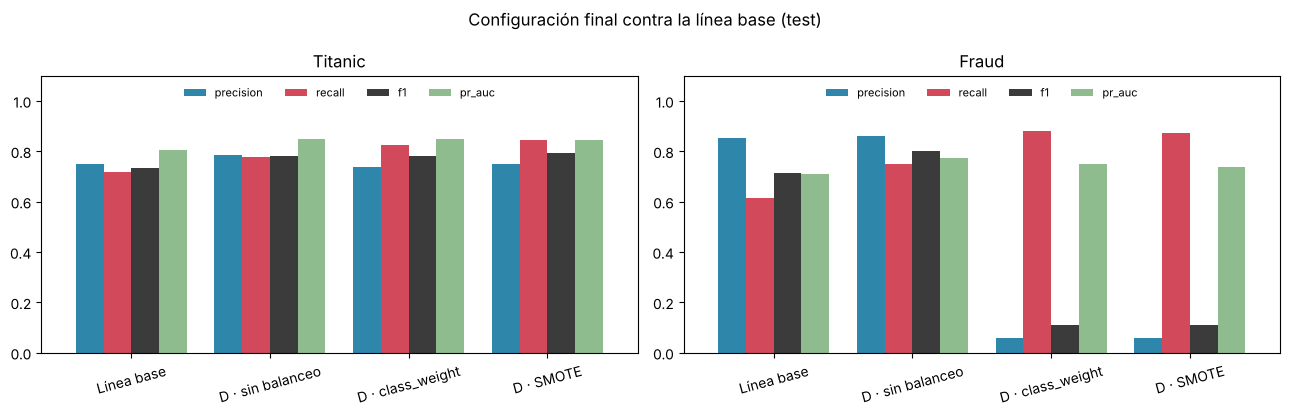

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for ax, ds in zip(axes, ["Titanic", "Fraud"]):
    t = final[final["dataset"] == ds].set_index("experimento")[["precision", "recall", "f1", "pr_auc"]]
    t.plot.bar(ax=ax, width=0.8, rot=15, color=["#2e86ab", "#d1495b", "#3b3b3b", "#8fbc8f"])
    ax.set_ylim(0, 1.1); ax.set_title(ds); ax.set_xlabel("")
    ax.legend(ncol=4, fontsize=8, loc="upper center", frameon=False)
fig.suptitle("Configuración final contra la línea base (test)")
plt.tight_layout(); plt.savefig("../figuras/a_final_comparacion.png", dpi=150); plt.show()

## 7. Conclusiones

**Titanic.** El preprocesamiento del Rol D sube el F1 de 0.733 (línea base) a 0.780, sobre todo por
imputar `Age` con la mediana por título: el título distingue a los niños ("Master"), que tuvieron
prioridad en los botes. Con desbalance leve (IR = 1.6), **SMOTE** da el mejor F1 (0.795) y el mejor
recall (0.845): detecta 87 de 103 sobrevivientes contra 74 de la línea base, a cambio de pocas falsas
alarmas más (29 contra 25). **Recomendación: configuración del Rol D + SMOTE** (o `class_weight`, casi igual
y sin crear datos sintéticos).

**Credit Card Fraud.** La winsorización P1–P99 es la mejora más grande del proyecto: recall de 0.615 a
0.750, F1 de 0.714 a 0.801 y PR-AUC de 0.708 a 0.773, **sin balancear**. El balanceo sube el recall a
~0.87 (≈ 130 de 148 fraudes), pero las falsas alarmas pasan de 18 a más de 2,000 y la precision cae a
0.06. **Recomendación:** la configuración del Rol D **sin balanceo** si revisar alarmas es costoso
(mejor F1 y PR-AUC); `class_weight='balanced'` si la prioridad es no dejar pasar fraudes, ajustando el
umbral de decisión con una partición de validación.

**Lo que aprendimos**
1. El **accuracy no sirve** con desbalance: en Fraud, predecir siempre "no fraude" da 99.83 %.
2. Un **outlier puede ser la señal**: en Fraud no se eliminan, solo se recortan al P1–P99.
3. Ajustar **todo solo con train** es lo que hace que estas cifras sean honestas: el test nunca se tocó.

**Limitaciones:** una sola partición Hold-Out (sin validación cruzada); un solo modelo
(regresión logística); `Time` en Fraud se conservó aunque funciona como un índice temporal que podría
no generalizar; y las variables `V1`–`V28` son anónimas (PCA), por lo que no se pueden interpretar.